# Cumulative Chemical Discovery Analysis

This notebook analyzes the NER results to visualize the rate of discovery of unique chemicals as more files are processed.


In [3]:
import json
import matplotlib.pyplot as plt
import os

# Path to the NER results file
file_path = "../searching_results/e2e_run_20251210_105347/literature_searching/ner_results/chemical_ner_results.json"

# Load the data
if os.path.exists(file_path):
    with open(file_path, 'r') as f:
        data = json.load(f)
    print(f"Loaded data from {file_path}")
else:
    print(f"File not found: {file_path}")
    data = {"per_file_results": []}


Loaded data from ../searching_results/e2e_run_20251210_105347/literature_searching/ner_results/chemical_ner_results.json


Total files processed: 112
Total unique chemicals found: 3254


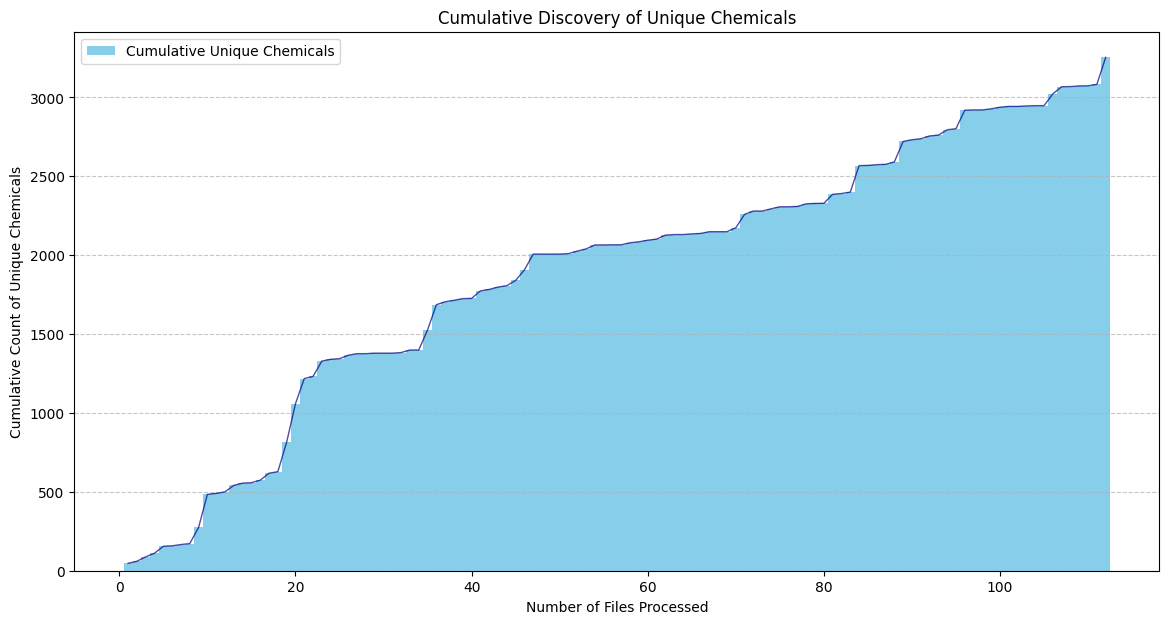

In [4]:
# Calculate cumulative unique chemicals
results = data.get("per_file_results", [])

cumulative_counts = []
seen_chemicals = set()

for i, res in enumerate(results):
    entities = res.get("entities", {})
    # Add new entities to the set of seen chemicals
    seen_chemicals.update(entities.keys())
    # Record the count of unique chemicals seen so far
    cumulative_counts.append(len(seen_chemicals))

print(f"Total files processed: {len(results)}")
print(f"Total unique chemicals found: {len(seen_chemicals)}")

# Plotting
plt.figure(figsize=(14, 7))
x_values = range(1, len(cumulative_counts) + 1)

# Create the bar plot
plt.bar(x_values, cumulative_counts, width=1.0, color='skyblue', edgecolor='none', label='Cumulative Unique Chemicals')

# Optional: Add a line on top to make the trend clearer
plt.plot(x_values, cumulative_counts, color='navy', linewidth=1, alpha=0.7)

plt.xlabel("Number of Files Processed")
plt.ylabel("Cumulative Count of Unique Chemicals")
plt.title("Cumulative Discovery of Unique Chemicals")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()

plt.show()